In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

## 1. Data Loading and Initial Inspection

In [4]:
# Load dataset
dataset = "../data/SupermarketEvaluation.csv"
df = pd.read_csv(dataset)
# Basic info
print("Dataset shape: ", df.shape)
print("\nColumns and their data types:")
print(df.dtypes)
print("\nFirst 3 rows :")
display(df.head(3))


Dataset shape:  (5000, 23)

Columns and their data types:
age                                     int64
household_income                      float64
gender                                 object
store_location                         object
typical_queue_wait_time               float64
distance_to_store                     float64
percent_self_service_checkout_uses    float64
children                                int64
fruit_and_veg_items                     int64
meat_items                              int64
cupboard_items                          int64
frozen_items                          float64
toiletries_items                      float64
other_items                             int64
has_loyalty_card                       object
brand_loyalty                          object
typical_visit_time                     object
typical_shopping_mission               object
brings_own_bag                         object
average_time_in_store                 float64
typical_payment_method

,age,household_income,gender,store_location,typical_queue_wait_time,distance_to_store,percent_self_service_checkout_uses,children,fruit_and_veg_items,meat_items,...,other_items,has_loyalty_card,brand_loyalty,typical_visit_time,typical_shopping_mission,brings_own_bag,average_time_in_store,typical_payment_method,satisfaction,Customer_Comment
0,45,55342.0,Male,Wymondham,18.3,1.9,0.36,1,22,5,...,2,No,Medium,Morning,Weekly shop,Yes,66.5,Cash,Low,Not the best visit on my way home doing just a...
1,52,65767.0,Female,Fakenham,9.5,1.1,0.16,0,4,0,...,5,No,High,Evening,Top-up,Yes,63.4,NaN,Low,I wasn’t very impressed this time this morning...
2,43,42301.0,Male,Dereham,18.8,2.5,0.30,1,11,1,...,6,No,High,Morning,Top-up,Yes,67.2,Google Pay,Low,NaN


## 2. Data Quality Assessment
### 2.1 Missing Values Analysis

In [5]:
# missing values overview
print("\nMissing values per column:")
missing = pd.DataFrame({
    'Missing': df.isna().sum(),
    'Percent': (df.isna().sum() / len(df) * 100).round(2)
}).sort_values('Missing', ascending=False)
display(missing[missing['Missing'] > 0])


Missing values per column:


,Missing,Percent
Customer_Comment,1577,31.54
distance_to_store,912,18.24
typical_payment_method,199,3.98
household_income,188,3.76
frozen_items,95,1.90
gender,81,1.62
toiletries_items,59,1.18
typical_queue_wait_time,48,0.96


### 2.2 Descriptive Statistics - Numerical Features

In [6]:
# descriptive statistics
print("\nNumerical columns summary:")
display(df.describe())


Numerical columns summary:


,age,household_income,typical_queue_wait_time,distance_to_store,percent_self_service_checkout_uses,children,fruit_and_veg_items,meat_items,cupboard_items,frozen_items,toiletries_items,other_items,average_time_in_store
count,5000.000000,4.812000e+03,4952.000000,4088.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,4905.000000,4941.000000,5000.000000,5000.000000
mean,48.790800,6.474890e+04,41.797920,1.954232,0.331838,0.756400,7.749800,4.123200,6.774400,3.974924,2.364906,3.079800,66.233060
std,33.874901,3.969892e+05,466.637391,1.330235,0.250311,0.924137,4.306984,3.682001,6.124198,3.732761,2.780538,2.034075,18.235361
min,20.000000,5.081000e+03,2.200000,0.300000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,27.000000
25%,31.000000,2.546500e+04,9.600000,1.100000,0.100000,0.000000,5.000000,1.000000,2.000000,1.000000,0.000000,2.000000,53.000000
50%,46.000000,3.595550e+04,12.000000,1.600000,0.300000,0.000000,7.000000,3.000000,5.000000,3.000000,1.000000,3.000000,63.700000
75%,60.000000,5.202925e+04,14.500000,2.300000,0.530000,1.000000,10.000000,6.000000,9.000000,6.000000,3.000000,4.000000,76.600000
max,367.000000,1.003282e+07,9920.400000,16.500000,0.970000,3.000000,39.000000,27.000000,54.000000,27.000000,20.000000,20.000000,184.300000


### 2.3 Descriptive Statistics - Categorical Features

In [7]:
print("\nCategorical columns value counts (top 5):")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(6))


Categorical columns value counts (top 5):

gender:
gender
Female               2192
Male                 2185
Non-binary            231
Prefer not to say     206
Other                 105
NaN                    81
Name: count, dtype: int64

store_location:
store_location
Wymondham    1004
Fakenham      975
Norwich       972
Dereham       955
Thetford      832
Derham          7
Name: count, dtype: int64

has_loyalty_card:
has_loyalty_card
No     2715
Yes    2285
Name: count, dtype: int64

brand_loyalty:
brand_loyalty
Medium    2266
Low       1462
High      1272
Name: count, dtype: int64

typical_visit_time:
typical_visit_time
Afternoon    1799
Evening      1681
Morning      1520
Name: count, dtype: int64

typical_shopping_mission:
typical_shopping_mission
Top-up         2067
Weekly shop    2045
Bulk shop       842
Weekly sop        3
To-up             3
Weekly hop        2
Name: count, dtype: int64

brings_own_bag:
brings_own_bag
Yes    2509
No     2491
Name: count, dtype: int64

typic

## 3. Data Dictionary
*(Based on raw data inspection)*

This table summarizes the 23 columns in SupermarketEvaluation.csv (5000 rows).  
Missing percentages and key statistics are taken directly from df.isna(), df.describe(), and value_counts().

| Column                              | Data Type | Description                                      | % Missing | Range / Unique Values / Key Stats                      | Key Issues / Observations                              |
|-------------------------------------|-----------|--------------------------------------------------|-----------|--------------------------------------------------------|--------------------------------------------------------|
| age                                 | int64     | Customer age                                     | 0.00      | min 20, max **367**, mean ≈48.8, 25%–75%: 31–60       | Unrealistic ages (>120, up to 367) -> clear data entry errors / outliers |
| household_income                    | float64   | Annual household income (£)                      | 3.76      | min ≈5k, max **~10M**, mean ≈64.7k                     | Extreme outliers (millions) -> likely typos or extra zeros |
| gender                              | object    | Gender identity                                  | 1.62      | Female (2192), Male (2185), Non-binary (231), Prefer not to say (206), Other (105) | Small missing %, otherwise clean categories            |
| store_location                      | object    | Supermarket branch / town                        | 0.00      | Wymondham (1004), Fakenham (975), Norwich (972), Dereham (955), Thetford (832), Derham (7) | Minor spelling variants / typos (e.g. Derham vs Dereham) low impact |
| typical_queue_wait_time             | float64   | Typical queue wait time (minutes)                | 0.96      | min 2.2, max **992** (suspect), mean ≈41.8            | Very high max value -> almost certainly an outlier / error |
| distance_to_store                   | float64   | Distance from home to store (miles)              | 18.24     | min 0.3, max 16.5                                      | **High missing rate** (18%) imputation or removal may be needed |
| percent_self_service_checkout_uses  | float64   | Proportion of self-checkout usage (0–1)          | 0.00      | min 0.0, max 0.97                                      | Plausible proportion values                            |
| children                            | int64     | Number of children in household                  | 0.00      | min 0, max 3 (mostly 0–1)                              | Clean, low cardinality                                 |
| fruit_and_veg_items                 | int64     | Count of fruit & vegetable items bought          | 0.00      | min 1?, max 39                                         | High values possible in bulk shops                     |
| meat_items                          | int64     | Count of meat items bought                       | 0.00      | min 0, max 27                                          | -                                                      |
| cupboard_items                      | int64     | Count of cupboard / dry goods items              | 0.00      | min 0, max 54                                          | High max possible for large shops                      |
| frozen_items                        | float64   | Count of frozen items                            | 1.90      | min 0, max 27                                          | Small missing %                                        |
| toiletries_items                    | float64   | Count of toiletries / personal care items        | 1.18      | min 0, max 20                                          | Small missing %                                        |
| other_items                         | int64     | Count of miscellaneous / other items             | 0.00      | min 0, max 20                                          | -                                                      |
| has_loyalty_card                    | object    | Customer has loyalty card                        | 0.00      | Yes (2285), No (2715)                                  | Clean binary field                                     |
| brand_loyalty                       | object    | Self-reported loyalty level                      | 0.00      | Medium (2266), Low (1462), High (1272)                 | Ordinal, useful for analysis                          |
| typical_visit_time                  | object    | Typical time of day for shopping                 | 0.00      | Afternoon (1799), Evening (1681), Morning (1520)       | Clean, fairly balanced                                 |
| typical_shopping_mission            | object    | Primary shopping purpose                         | 0.00      | Top-up (2067), Weekly shop (2045), Bulk shop (842), Weekly sop (3), To-up (3) | Minor rare typos (low count) can be cleaned easily   |
| brings_own_bag                      | object    | Brings own reusable bag                          | 0.00      | Yes (2509), No (2491)                                  | Clean binary                                           |
| average_time_in_store               | float64   | Typical time spent in store (minutes)            | 0.00      | min 27, max 184, mean ≈66.2                            | Plausible range for shopping times                     |
| typical_payment_method              | object    | Most common payment method                       | 3.98      | Card (2727), Cash (1016), Apple Pay (586), Google Pay (262), Unknown (196) | Some missing + minor noise (Unknown)                   |
| satisfaction                        | object    | Overall satisfaction rating                      | 0.00      | Medium (1105), High (991), Very High (981), Low (966), Very Low (957) | Balanced 5-level ordinal **strong candidate target variable** |
| Customer_Comment                    | object    | Free-text feedback comment                       | 31.54     | 3423 non-null entries                                  | **High missing rate** limits full text mining        |

## 4. Initial Data Visualization - Outlier Detection

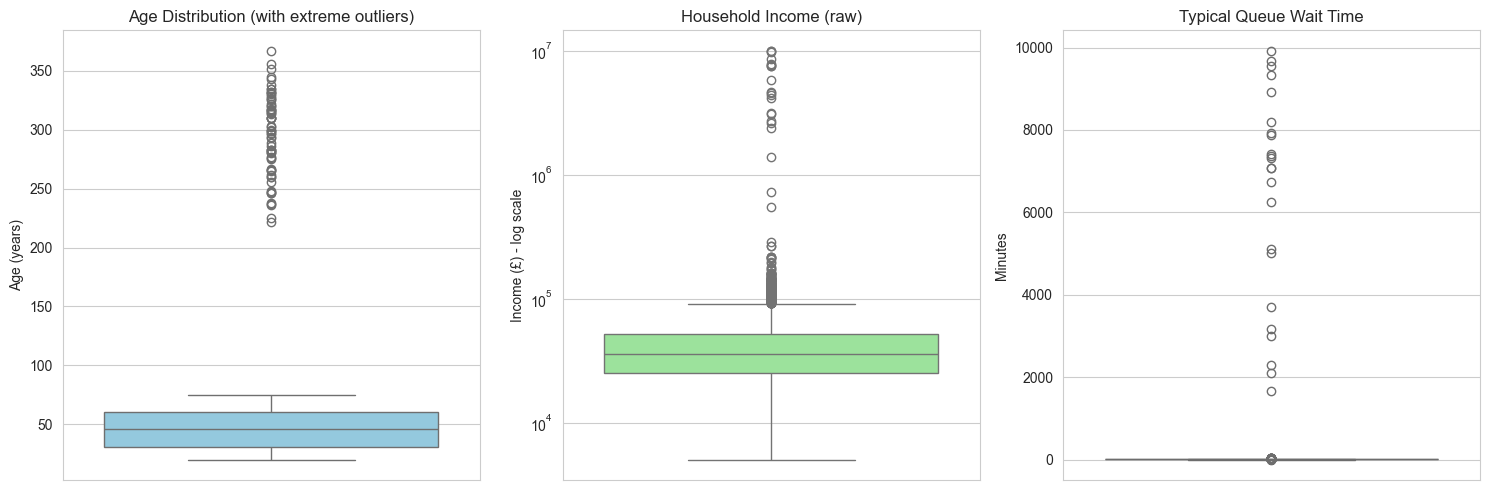

In [8]:
# Boxplots of problematic numerical columns

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Age
sns.boxplot(y=df['age'], ax=axes[0], color='skyblue')
axes[0].set_title('Age Distribution (with extreme outliers)')
axes[0].set_ylabel('Age (years)')

# Household income
sns.boxplot(y=df['household_income'], ax=axes[1], color='lightgreen')
axes[1].set_title('Household Income (raw)')
axes[1].set_yscale('log')
axes[1].set_ylabel('Income (£) - log scale')

# Queue wait time
sns.boxplot(y=df['typical_queue_wait_time'], ax=axes[2], color='salmon')
axes[2].set_title('Typical Queue Wait Time')
axes[2].set_ylabel('Minutes')

plt.tight_layout()
plt.savefig('../figures/01_boxplots_outliers_raw.png', dpi=150, bbox_inches='tight')
plt.show()

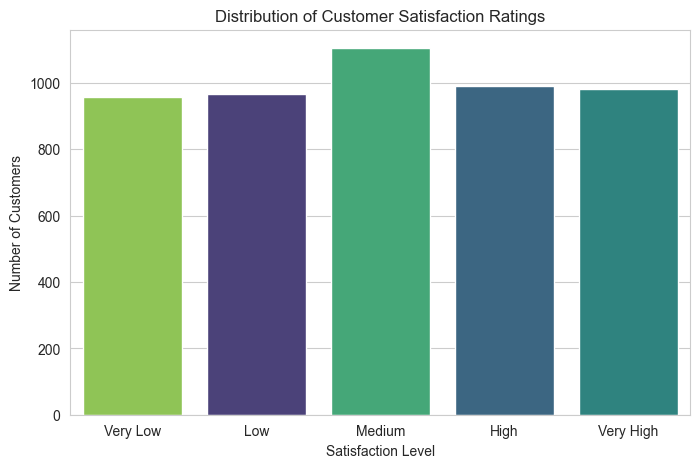

In [9]:
# Satisfaction levels
plt.figure(figsize=(8, 5))
order = ['Very Low', 'Low', 'Medium', 'High', 'Very High']
sns.countplot(
    x='satisfaction',
    data=df,
    order=order,
    hue='satisfaction',
    palette='viridis',
    legend=False
)
plt.title('Distribution of Customer Satisfaction Ratings')
plt.xlabel('Satisfaction Level')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.savefig('../figures/02_satisfaction_distribution.png', 
            dpi=150, 
            bbox_inches='tight')
plt.show()

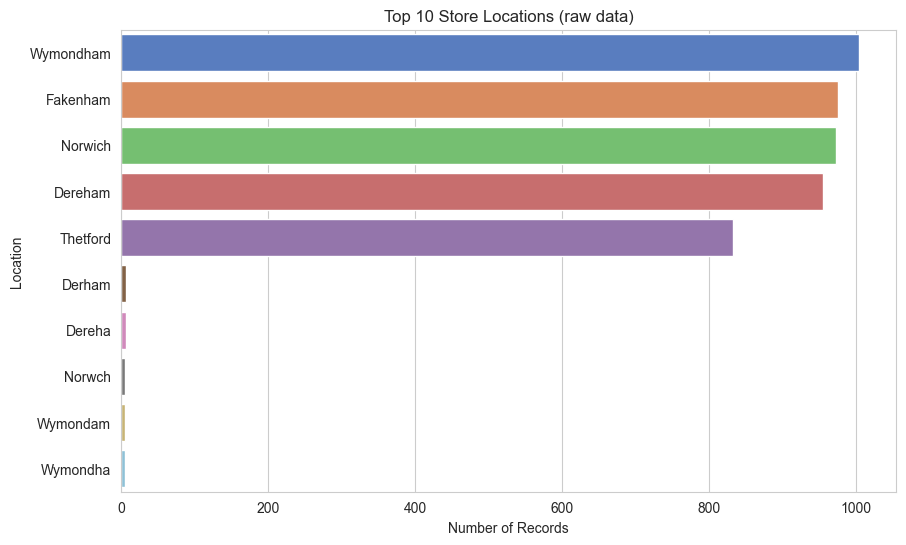

In [10]:
# Store locations
plt.figure(figsize=(10, 6))
top_locations = df['store_location'].value_counts().head(10)
sns.barplot(
    x=top_locations.values,
    y=top_locations.index,
    hue=top_locations.index,
    palette='muted',
    legend=False
)
plt.title('Top 10 Store Locations (raw data)')
plt.xlabel('Number of Records')
plt.ylabel('Location')
plt.savefig('../figures/03_store_locations_top10.png',
            dpi=150,
            bbox_inches='tight')
plt.show()

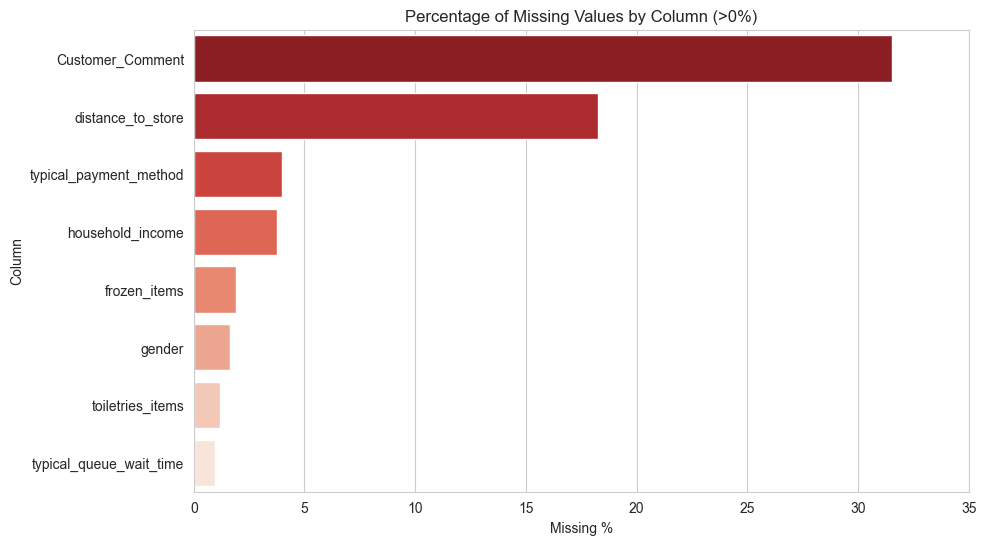

In [11]:
# Missing values overview
missing = df.isna().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing.values,
    y=missing.index,
    hue=missing.index,
    palette='Reds_r',
    legend=False
)
plt.title('Percentage of Missing Values by Column (>0%)')
plt.xlabel('Missing %')
plt.ylabel('Column')
plt.xlim(0, 35)
plt.savefig('../figures/04_missing_values_bar.png',
            dpi=150,
            bbox_inches='tight')
plt.show()

## 5. Data Cleaning and Transformation
### 5.1 Handling Outliers

In [12]:
# Light Data Cleaning & Transformation 
df_clean = df.copy()
print("Shape before change:", df_clean.shape)

# Clip unrealistic ages (18–100 range is reasonable)
df_clean['age'] = df_clean['age'].clip(lower=18, upper=100)
print("Age after clipping -> min:", df_clean['age'].min(), "max:", df_clean['age'].max())

# Cap household_income 
# Anything above (e.g. 500,000 £) is almost certainly a data entry error
income_cap = 500000
df_clean['household_income'] = df_clean['household_income'].clip(upper=income_cap)
print(f"Household income capped at £{income_cap:,} -> max now:", df_clean['household_income'].max())

# Fix extreme queue wait time (anything > 60 minutes is unrealistic)
wait_cap = 60
df_clean['typical_queue_wait_time'] = df_clean['typical_queue_wait_time'].clip(upper=wait_cap)
print("Queue wait time capped at 60 min -> max now:", df_clean['typical_queue_wait_time'].max())

Shape before change: (5000, 23)
Age after clipping -> min: 20 max: 100
Household income capped at £500,000 -> max now: 500000.0
Queue wait time capped at 60 min -> max now: 60.0


### 5.2 Standardizing Categorical Variables

In [13]:
location_mapping = {
    # Wymondham
    'Wymondam': 'Wymondham',
    'Wymondha': 'Wymondham',
    'Wyymondham': 'Wymondham',
    'Wymndham': 'Wymondham',
    'Wyondham': 'Wymondham',
    'Wymodham': 'Wymondham',
    'Wymonham': 'Wymondham',
    'ymondham': 'Wymondham',
    'Wymjondham': 'Wymondham',
    'Wymondhaam': 'Wymondham',
    'Wymonjdham': 'Wymondham',
    'Wmondham': 'Wymondham',
    'Wymovndham': 'Wymondham',
    'jWymondham': 'Wymondham',
    'Wymondha m': 'Wymondham',
    'Wynmondham': 'Wymondham',
    'Wymbondham': 'Wymondham',
    'Wymondhamy': 'Wymondham',
    'Wymondhuam': 'Wymondham',
    'Wymondmham': 'Wymondham',
    'Wymondhm': 'Wymondham',
    'Whymondham': 'Wymondham',
    'Wymondhazm': 'Wymondham',
    'Wymoundham': 'Wymondham',
    'Wymondhram': 'Wymondham',
    'Weymondham': 'Wymondham',
    'Wymondwham': 'Wymondham',
    'Wyxmondham': 'Wymondham',

    # Fakenham
    'F akenham': 'Fakenham',
    'Fakenhamz': 'Fakenham',
    'Faenham': 'Fakenham',
    'Faknham': 'Fakenham',
    'Fakenha': 'Fakenham',
    'Fakeham': 'Fakenham',
    'Fkenham': 'Fakenham',
    'Fakenhm': 'Fakenham',
    'yFakenham': 'Fakenham',
    'Fakenhamy': 'Fakenham',
    'Fakdenham': 'Fakenham',
    'Fakenam': 'Fakenham',
    'Fpakenham': 'Fakenham',
    'Fakenhafm': 'Fakenham',
    'Fakepnham': 'Fakenham',
    'Fiakenham': 'Fakenham',
    'Fakpenham': 'Fakenham',
    'akenham': 'Fakenham',
    'Fakenhagm': 'Fakenham',
    'Fhakenham': 'Fakenham',
    'Fakecnham': 'Fakenham',
    'Fabkenham': 'Fakenham',
    'Fakenhqam': 'Fakenham',
    'Fakenhavm': 'Fakenham',
    'Fyakenham': 'Fakenham',
    'Fakenlham': 'Fakenham',
    'Fjakenham': 'Fakenham',
    'Fakenhamr': 'Fakenham',
    'Fakmenham': 'Fakenham',
    'Fakeniham': 'Fakenham',
    'Fakenhapm': 'Fakenham',
    'Fakenheam': 'Fakenham',
    'Fakenhabm': 'Fakenham',
    'Fakenhaam': 'Fakenham',
    'Fakehnham': 'Fakenham',

    # Norwich
    'Norwch': 'Norwich',
    'Norwdich': 'Norwich',
    'Norwic': 'Norwich',
    'Nrwich': 'Norwich',
    'Norwih': 'Norwich',
    'Nowich': 'Norwich',
    'Norich': 'Norwich',
    'Nforwich': 'Norwich',
    'Nnorwich': 'Norwich',
    'orwich': 'Norwich',
    'nNorwich': 'Norwich',
    'Norwichm': 'Norwich',
    'Nolrwich': 'Norwich',
    'yNorwich': 'Norwich',
    'Norzwich': 'Norwich',
    'Norfwich': 'Norwich',
    'aNorwich': 'Norwich',
    'Nporwich': 'Norwich',
    'Norrwich': 'Norwich',
    'Norwipch': 'Norwich',
    'Norwichd': 'Norwich',
    'Norwwich': 'Norwich',
    'Nowrwich': 'Norwich',
    'eNorwich': 'Norwich',
    'Norwsich': 'Norwich',
    'Nokrwich': 'Norwich',
    'Norwichx': 'Norwich',
    'Norwichl': 'Norwich',
    ' Norwich': 'Norwich',
    'Noriwich': 'Norwich',
    'Norwigch': 'Norwich',

    # Dereham
    'Dereha': 'Dereham',
    'Derham': 'Dereham',
    'ereham': 'Dereham',
    'Deream': 'Dereham',
    'Derehm': 'Dereham',
    'Deeham': 'Dereham',
    'Dreham': 'Dereham',
    'Dbereham': 'Dereham',
    'Defreham': 'Dereham',
    'Derteham': 'Dereham',
    'Derehakm': 'Dereham',
    'Derehacm': 'Dereham',
    'Derpeham': 'Dereham',
    'Derebham': 'Dereham',
    'Duereham': 'Dereham',
    'Derehamb': 'Dereham',
    'mDereham': 'Dereham',
    'Diereham': 'Dereham',
    'Dereheam': 'Dereham',
    'qDereham': 'Dereham',
    'Derepham': 'Dereham',
    'Derehpam': 'Dereham',
    'Derehahm': 'Dereham',
    'Dqereham': 'Dereham',
    'Derehamq': 'Dereham',
    'Derevham': 'Dereham',
    'Dtereham': 'Dereham',
    'Degreham': 'Dereham',
    'Derreham': 'Dereham',
    'gDereham': 'Dereham',
    'pDereham': 'Dereham',
    'Derehamw': 'Dereham',

    # Thetford
    'Thetord': 'Thetford',
    'Tetford': 'Thetford',
    'Theford': 'Thetford',
    'Thetfod': 'Thetford',
    'hetford': 'Thetford',
    'Thetfrd': 'Thetford',
    'Thtford': 'Thetford',
    'Thhetford': 'Thetford',
    'Thertford': 'Thetford',
    'Thetfford': 'Thetford',
    'Thetforkd': 'Thetford',
    'T hetford': 'Thetford',
    'Thetforwd': 'Thetford',
    'Tzhetford': 'Thetford',
    'Thoetford': 'Thetford',
    'Thetfordt': 'Thetford',
    'Thsetford': 'Thetford',
    'Thbetford': 'Thetford',
    'Thetfmord': 'Thetford',
    'Thetzford': 'Thetford',
    'Thwetford': 'Thetford',
    'Thetfxord': 'Thetford',
    'Thedtford': 'Thetford',
    'Thetlford': 'Thetford',
    'Thetfordr': 'Thetford',
    'aThetford': 'Thetford',
    'Thetfosrd': 'Thetford',
    'Thetfordw': 'Thetford',
    'Thetfordo': 'Thetford',
    'Theetford': 'Thetford',
    'uThetford': 'Thetford'
}

df_clean['store_location'] = df_clean['store_location'].replace(location_mapping)
print("\nStore locations after simple cleaning:")
print(df_clean['store_location'].value_counts())


Store locations after simple cleaning:
store_location
Wymondham    1058
Fakenham     1031
Norwich      1025
Dereham      1010
Thetford      876
Name: count, dtype: int64


### 5.3 Cleaning Shopping Mission

In [15]:
mission_mapping = {
    # All weekly shop variants
    'Weekly sop': 'Weekly shop',
    'Weekly hop': 'Weekly shop',
    'Weeky shop': 'Weekly shop',
    'Weekl shop': 'Weekly shop',
    'Weekly shp': 'Weekly shop',
    'Weekly shoup': 'Weekly shop',
    'Weekly shoop': 'Weekly shop',
    'Weekly shuop': 'Weekly shop',
    'Weely shop': 'Weekly shop',
    'Weaekly shop': 'Weekly shop',
    'Weevkly shop': 'Weekly shop',
    'Wezekly shop': 'Weekly shop',
    'Weyekly shop': 'Weekly shop',
    'Weehkly shop': 'Weekly shop',
    'Weeklvy shop': 'Weekly shop',
    'Weekxly shop': 'Weekly shop',
    'Weekly sho': 'Weekly shop',

    # All top-up variants
    'To-up': 'Top-up',
    'Top-u': 'Top-up',
    'Topup': 'Top-up',
    'Top-uup': 'Top-up',
    'Top-upy': 'Top-up',
    'Top-upq': 'Top-up',
    'Tp-up': 'Top-up',
    'Trop-up': 'Top-up',
    'Toqp-up': 'Top-up',
    'Top-tup': 'Top-up',
    'Top-lup': 'Top-up',
    'fTop-up': 'Top-up',
    'zTop-up': 'Top-up',
    'op-up': 'Top-up',
    'Tobp-up': 'Top-up',
    'Topupq': 'Top-up',   # if any similar

    # All bulk variants
    'Bulk shohp': 'Bulk shop',
    'Buglk shop': 'Bulk shop',
    'Bulk shqop': 'Bulk shop',
    'Bulk sho': 'Bulk shop',
    'Bulke shop': 'Bulk shop'
}

df_clean['typical_shopping_mission'] = df_clean['typical_shopping_mission'].replace(mission_mapping)
print("\nShopping mission after collapse:")
print(df_clean['typical_shopping_mission'].value_counts())

# Total_items feature
item_cols = ['fruit_and_veg_items', 'meat_items', 'cupboard_items', 'frozen_items',
             'toiletries_items', 'other_items']



Shopping mission after collapse:
typical_shopping_mission
Top-up         2085
Weekly shop    2068
Bulk shop       847
Name: count, dtype: int64


### 5.4 Feature Engineering

In [16]:
# Total_items feature
item_cols = ['fruit_and_veg_items', 'meat_items', 'cupboard_items', 'frozen_items',
             'toiletries_items', 'other_items']

df_clean['total_items'] = df_clean[item_cols].sum(axis=1, skipna=True)
print("\nNew column 'total_items' created -> describe:")
print(df_clean['total_items'].describe())


New column 'total_items' created -> describe:
count    5000.000000
mean       27.963600
std        13.494336
min         7.000000
25%        16.000000
50%        27.000000
75%        37.000000
max        69.000000
Name: total_items, dtype: float64


## 6. Exploratory Data Analysis (EDA) on Cleaned Data
### 6.1 Distribution of Cleaned Numerical Features

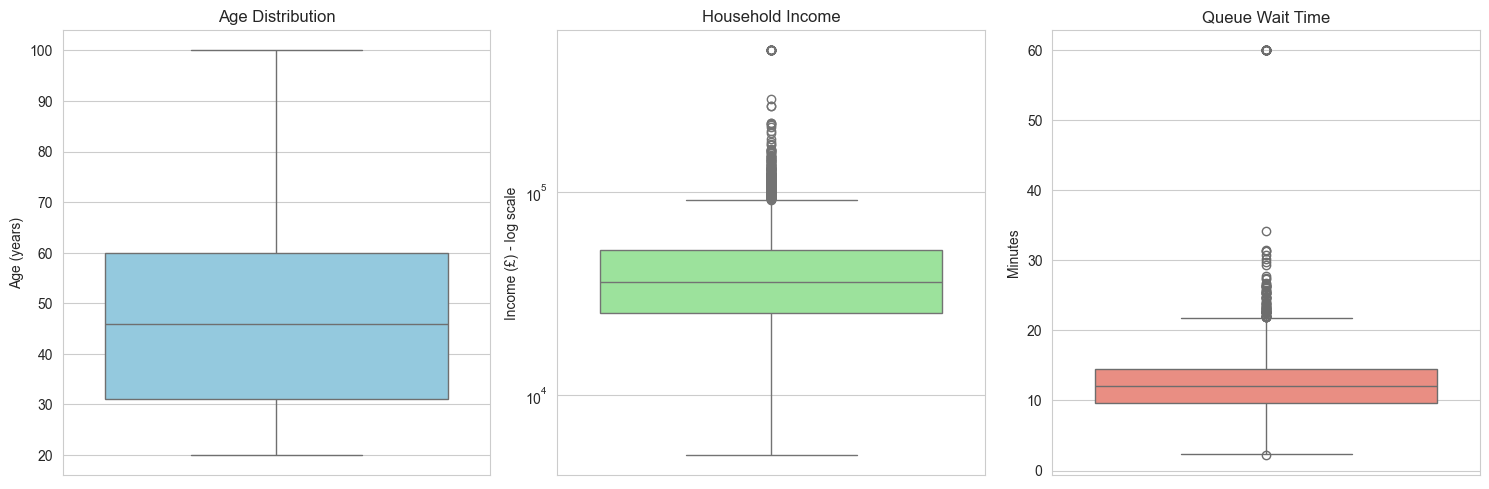

In [17]:
# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Age
sns.boxplot(y=df_clean['age'], ax=axes[0], color='skyblue')
axes[0].set_title('Age Distribution')
axes[0].set_ylabel('Age (years)')

# Household income
sns.boxplot(y=df_clean['household_income'], ax=axes[1], color='lightgreen')
axes[1].set_title('Household Income')
axes[1].set_yscale('log')
axes[1].set_ylabel('Income (£) - log scale')

# Queue wait time
sns.boxplot(y=df_clean['typical_queue_wait_time'], ax=axes[2], color='salmon')
axes[2].set_title('Queue Wait Time')
axes[2].set_ylabel('Minutes')

plt.tight_layout()
plt.savefig('../figures/01_boxplots_outliers_clean.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.2 Satisfaction Analysis by Shopping Mission

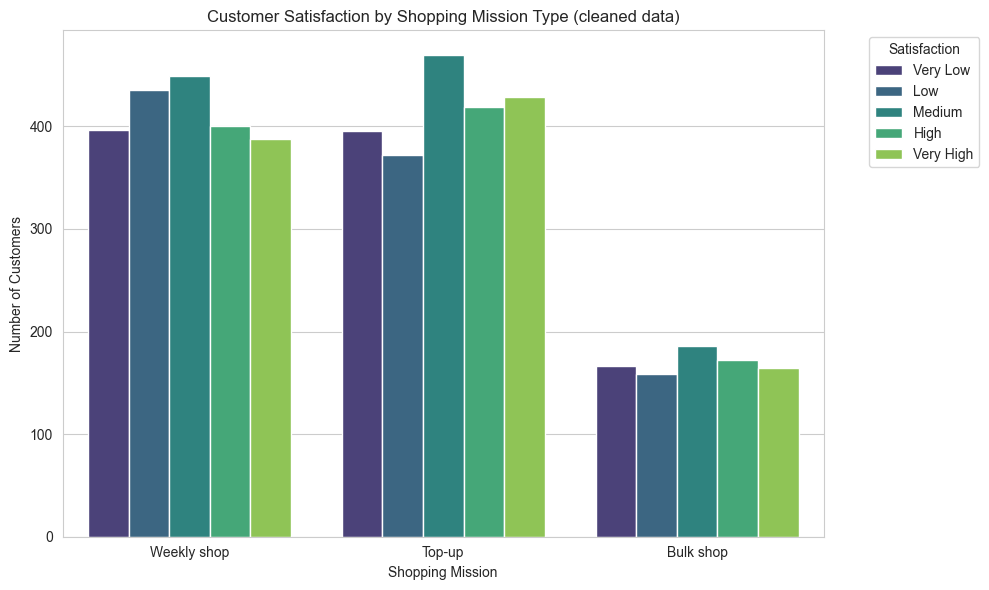

In [18]:
# Satisfaction by shopping mission (cleaned)
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_clean,
    x='typical_shopping_mission',
    hue='satisfaction',
    hue_order=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
    palette='viridis'
)
plt.title('Customer Satisfaction by Shopping Mission Type (cleaned data)')
plt.xlabel('Shopping Mission')
plt.ylabel('Number of Customers')
plt.legend(title='Satisfaction', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../figures/05_satisfaction_by_mission.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.3 Satisfaction Analysis by Age Group

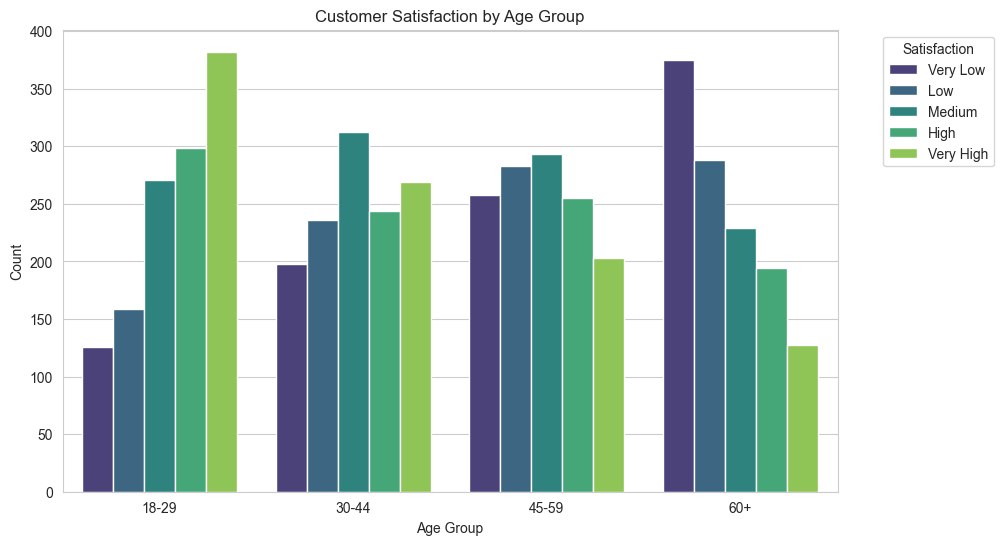

In [19]:
# Bin age into groups
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[18, 30, 45, 60, 100],
    labels=['18-29', '30-44', '45-59', '60+'],
    include_lowest=True
)

plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_clean,
    x='age_group',
    hue='satisfaction',
    hue_order=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
    palette='viridis'
)
plt.title('Customer Satisfaction by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.legend(title='Satisfaction', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('../figures/06_satisfaction_by_age_group.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.4 Satisfaction Analysis by Loyalty Card Status

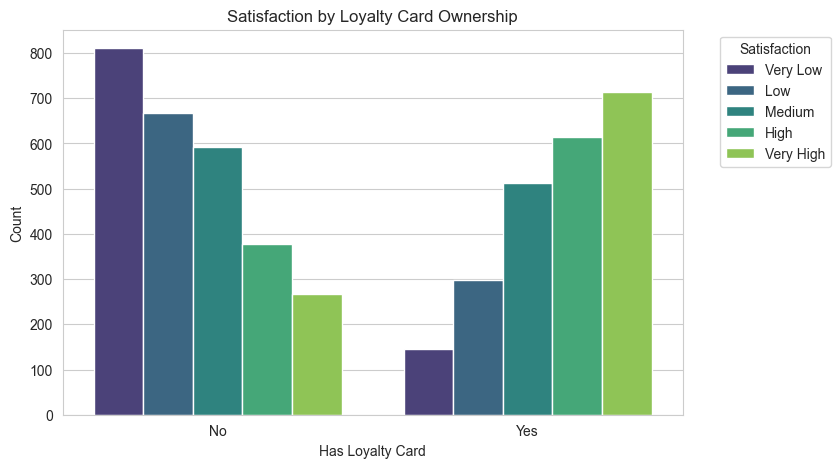

In [20]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_clean,
    x='has_loyalty_card',
    hue='satisfaction',
    hue_order=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
    palette='viridis'
)
plt.title('Satisfaction by Loyalty Card Ownership')
plt.xlabel('Has Loyalty Card')
plt.ylabel('Count')
plt.legend(title='Satisfaction', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('../figures/07_satisfaction_by_loyalty_card.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.5 Relationship Between Time in Store and Satisfaction

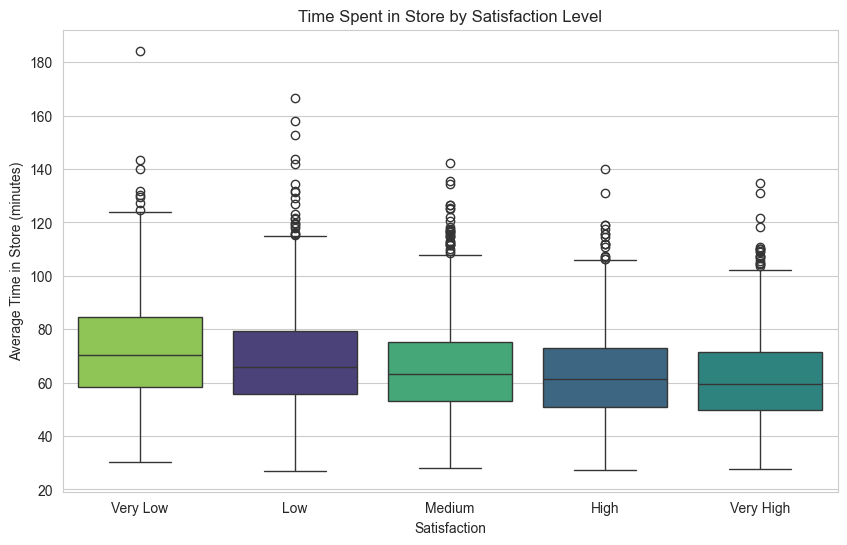

In [21]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='satisfaction',
    y='average_time_in_store',
    order=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
    hue='satisfaction',
    palette='viridis',
    legend=False
)

plt.title('Time Spent in Store by Satisfaction Level')
plt.xlabel('Satisfaction')
plt.ylabel('Average Time in Store (minutes)')

plt.savefig(
    '../figures/08_time_in_store_by_satisfaction.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

### 6.6 Relationship Between Basket Size and Satisfaction

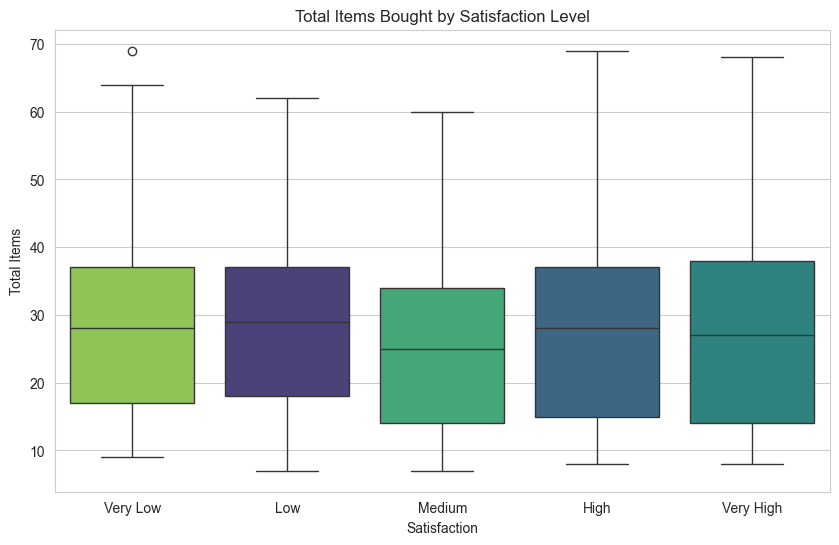

In [22]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='satisfaction',
    y='total_items',
    order=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
    hue='satisfaction',
    palette='viridis',
    legend=False
)

plt.title('Total Items Bought by Satisfaction Level')
plt.xlabel('Satisfaction')
plt.ylabel('Total Items')

plt.savefig(
    '../figures/09_total_items_by_satisfaction.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

## 7. Summary and Next Steps

### 7.1 Key Findings

Based on the preliminary analysis:

1. **Data Quality:** The dataset has been successfully cleaned. Outliers in `age`, `household_income`, and `typical_queue_wait_time` have been handled. Categorical inconsistencies in `store_location` and `typical_shopping_mission` have been standardized.

2. **Data Dictionary:** A comprehensive data dictionary has been created (see Section 3), documenting all 23 features, their data types, missing percentages, ranges, and key observations.

3. **Predictive Task:** A multi-class classification task to predict `satisfaction` (5 levels: Very Low to Very High) is feasible and appropriate.

4. **Key Predictors Identified:**
   - **Loyalty Card:** Strong positive correlation with satisfaction
   - **Time in Store:** Inverse relationship with satisfaction
   - **Shopping Mission:** Bulk shops associated with lower satisfaction
   - **Age Group:** Older customers (60+) show more negative ratings
   - **Basket Size (total_items):** May influence satisfaction

5. **Data Suitability:** The cleaned dataset is well-suited for the proposed task. The target variable is well-balanced across all five satisfaction levels.

### 7.2 Recommended Next Steps for Data Mining Phase

To prepare for the predictive modeling phase, the following steps are recommended:

1. **Handle Remaining Missing Values:**
   - For numerical features with <5% missing (`household_income`, `frozen_items`, etc.), consider mean/median imputation
   - For `typical_payment_method` (3.98% missing), mode imputation
   - Exclude `Customer_Comment` and `distance_to_store` from initial model due to high missingness

2. **Encode Categorical Variables:**
   - Apply one-hot encoding to nominal features: `gender`, `store_location`, `typical_visit_time`, `typical_payment_method`, `brings_own_bag`
   - Apply label encoding to ordinal features: `satisfaction` (target), `brand_loyalty`

3. **Feature Scaling:**
   - Apply standardization (Z-score) or normalization (Min-Max) to numerical features

4. **Train-Test Split:**
   - Split data into training (70-80%) and testing (20-30%) sets
   - Ensure stratification to maintain class distribution

5. **Model Selection:**
   - Consider classification algorithms such as:
     - Random Forest (handles non-linear relationships well)
     - Gradient Boosting (XGBoost, LightGBM)
     - Logistic Regression (as a baseline)

6. **Evaluation Metrics:**
   - Use accuracy, precision, recall, F1-score, and confusion matrix
   - Given balanced classes, macro/micro-averaged metrics will be appropriate

### 7.3 Suggested Future Data Collection

To enhance future models, consider collecting:

- **Operational Data:** Staffing levels, number of open checkouts by hour
- **External Factors:** Local events, weather conditions during visits
- **Longitudinal Data:** Track individual customers over multiple visits
- **Product Availability:** Stock-out incidents during customer visits